In [3]:
import pandas as pd
df = pd.read_csv("../results/timings.csv")
df = df[df["experiment"].str.match(r"E[4-6]")].copy()

df["ns_per_op"] = df["total_ns"] / df["n_ops"]
for c in ["comparisons", "nodes_visited", "rotations", "splits", "resizes"]:
    df[c + "_per_op"] = df[c] / df["n_ops"]

keys = ["experiment", "code_version", "index_type", "index_param",
        "insert_order", "n_keys", "operation", "operation_param"]
summary = (df.groupby(keys, dropna=False)
             .agg(median_ns=("ns_per_op", "median"),
                  height=("height", "max"),
                  comparisons=("comparisons_per_op", "median"),
                  nodes=("nodes_visited_per_op", "median"),
                  rotations=("rotations", "median"),
                  splits=("splits", "median"),
                  resizes=("resizes", "median"))
             .reset_index())
summary

,experiment,code_version,index_type,index_param,insert_order,n_keys,operation,operation_param,median_ns,height,comparisons,nodes,rotations,splits,resizes
0,E4_prefix_track,0dd46d8,avl_tree,NaN,file,113999,prefix,1.00,2.477959e+06,NaN,3179.410000,3179.410000,0.0,0.0,0.0
1,E4_prefix_track,0dd46d8,avl_tree,NaN,file,113999,prefix,2.00,4.526758e+05,NaN,617.040000,617.040000,0.0,0.0,0.0
2,E4_prefix_track,0dd46d8,avl_tree,NaN,file,113999,prefix,3.00,1.413408e+05,NaN,195.830000,195.830000,0.0,0.0,0.0
3,E4_prefix_track,0dd46d8,avl_tree,NaN,file,113999,prefix,4.00,1.198267e+05,NaN,175.330000,175.330000,0.0,0.0,0.0
4,E4_prefix_track,0dd46d8,avl_tree,NaN,file,113999,prefix,5.00,3.011541e+04,NaN,40.910000,40.910000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
748,E6_bplus_order,e738e1e,bplus_tree,order=64,file,114000,range,0.01,1.683246e+06,3.0,45653.000000,1082.000000,0.0,0.0,0.0
749,E6_bplus_order,e738e1e,bplus_tree,order=8,file,114000,build,NaN,2.962881e+03,7.0,15.481154,6.180798,0.0,16168.0,0.0
750,E6_bplus_order,e738e1e,bplus_tree,order=8,file,114000,point_hit,1.00,3.613750e+03,7.0,17.314000,7.000000,0.0,0.0,0.0
751,E6_bplus_order,e738e1e,bplus_tree,order=8,file,114000,point_miss,0.00,2.092416e+03,7.0,13.602000,7.000000,0.0,0.0,0.0


In [4]:
import matplotlib.pyplot as plt

df = pd.read_csv("../results/timings.csv")
df["per_op_ns"] = df.total_ns / df.n_ops
df["cmp_per_op"] = df.comparisons / df.n_ops
df["nodes_per_op"] = df.nodes_visited / df.n_ops

print(df.shape)
print(df.groupby(["experiment", "code_version"]).size())

(7303, 36)
experiment       code_version 
CORE             4b83e77          210
                 7b30652          208
                 9484d33          210
                 f134a99          210
E1_build         0dd46d8          210
                 31da8dc          210
                 eb3808a          210
E2_point_lookup  0dd46d8          420
                 3c45879          420
                 c2406c6          420
E3_range_tempo   0dd46d8          210
                 5be54e9          210
                 e4a0cfb          210
E4_prefix_track  0dd46d8          175
                 e4a0cfb          175
                 f24508f          175
E5_key_order     3d6cb30-dirty    840
                 684e1a6          840
                 e738e1e          840
E6_bplus_order   3d6cb30-dirty    225
                 c55dc8b          225
                 e4a0cfb          225
                 e738e1e          225
dtype: int64


In [6]:
import numpy as np

versions = {"e738e1e": "before", "684e1a6": "after"}

avl = df[(df.experiment == "E5_key_order") & (df.index_type == "avl_tree")
         & (df.operation == "build") & df.code_version.isin(versions)].copy()
avl["version"] = avl.code_version.map(versions)
avl["rot_per_insert"] = avl.rotations / avl.n_keys
avl["build_ms"] = avl.total_ns / 1e6

inc03 = (avl.groupby(["n_keys", "insert_order", "version"])
            .agg(height=("height", "max"),
                 rot_per_insert=("rot_per_insert", "median"),
                 build_ms=("build_ms", "median"))
            .unstack("version")
            .reindex(columns=["before", "after"], level=1)
            .round(2))

bound = {int(n): round(float(1.44 * np.log2(n + 2) - 0.33), 1) for n in sorted(avl.n_keys.unique())}
print("Maximum possible AVL height:", bound)
inc03

Maximum possible AVL height: {10000: 18.8, 50000: 22.1, 100000: 23.6}


height       rot_per_insert       build_ms        
version              before after         before after   before   after
n_keys insert_order                                                    
10000  nearly_sorted   20.0  16.0           8.40  1.21    75.14   55.21
       random          20.0  16.0          10.20  0.70    87.57   49.27
       reversed        17.0  14.0           8.64  1.00    65.03   48.62
       sorted          17.0  14.0           8.64  1.00    66.72   52.84
50000  nearly_sorted   23.0  18.0           9.75  1.19   448.43  335.92
       random          23.0  19.0          13.26  0.70   566.93  289.69
       reversed        20.0  16.0          10.53  1.00   385.17  288.71
       sorted          20.0  16.0          10.53  1.00   405.41  313.59
100000 nearly_sorted   28.0  20.0          10.30  1.20   938.05  726.52
       random          25.0  20.0          14.60  0.70  1224.09  653.03
       reversed        21.0  17.0          11.39  1.00   831.22  615.91
       sorted          21.0  17.0          11.39  1.00   891.92  655.69

In [7]:
versions = {"5be54e9": "before", "e4a0cfb": "after"}

e3 = df[(df.experiment == "E3_range_tempo") & (df.index_type == "bplus_tree")
        & df.code_version.isin(versions)].copy()
e3["version"] = e3.code_version.map(versions)

inc04_e3 = (e3.groupby(["operation_param", "version"])
               .agg(cmp_per_query=("cmp_per_op", "median"),
                    nodes_per_query=("nodes_per_op", "median"),
                    us_per_query=("per_op_ns", lambda s: s.median() / 1000))
               .unstack("version")
               .reindex(columns=["before", "after"], level=1)
               .round(1))
inc04_e3.index.name = "selectivity"
inc04_e3

cmp_per_query          nodes_per_query        us_per_query        
version            before    after          before  after       before   after
selectivity                                                                   
0.0001            45653.0     21.6          2197.0    4.2       1881.2     4.0
0.0010            45653.0     62.8          2197.0    6.1       1915.6    16.1
0.0100            45653.0    473.9          2197.0   25.0       1977.2   134.0
0.0500            45653.0   2299.8          2197.0  109.2       2196.2   465.3
0.1000            45653.0   4581.6          2197.0  213.8       2362.7  1053.1
0.2500            45653.0  11429.7          2197.0  528.9       2737.1  2788.7

In [8]:
versions = {"f24508f": "before", "e4a0cfb": "after"}

e4 = df[(df.experiment == "E4_prefix_track") & (df.index_type == "bplus_tree")
        & df.code_version.isin(versions)].copy()
e4["version"] = e4.code_version.map(versions)

inc04_e4 = (e4.groupby(["operation_param", "version"])
               .agg(cmp_per_query=("cmp_per_op", "median"),
                    nodes_per_query=("nodes_per_op", "median"),
                    us_per_query=("per_op_ns", lambda s: s.median() / 1000))
               .unstack("version")
               .reindex(columns=["before", "after"], level=1)
               .round(1))
inc04_e4.index.name = "prefix_length"
inc04_e4

cmp_per_query         nodes_per_query        us_per_query       
version              before   after          before  after       before  after
prefix_length                                                                 
1.0                 72396.0  3179.9          3497.0  150.4       7984.4  873.2
2.0                 72396.0   616.4          3497.0   31.5       7389.0  195.2
3.0                 72396.0   195.0          3497.0   12.2       7480.2   52.9
4.0                 72396.0   175.4          3497.0   11.4       7188.7   40.7
5.0                 72396.0    40.9          3497.0    5.1       7486.6   10.4

In [9]:
versions = {"e738e1e": "before", "e4a0cfb": "after"}

e6 = df[(df.experiment == "E6_bplus_order") & (df.operation == "range")
        & df.code_version.isin(versions)].copy()
e6["version"] = e6.code_version.map(versions)
e6["order"] = e6.index_param.str.replace("order=", "").astype(int)

inc04_e6 = (e6.groupby(["order", "version"])
               .agg(cmp_per_query=("cmp_per_op", "median"),
                    nodes_per_query=("nodes_per_op", "median"),
                    us_per_query=("per_op_ns", lambda s: s.median() / 1000))
               .unstack("version")
               .reindex(columns=["before", "after"], level=1)
               .round(1))
inc04_e6

cmp_per_query        nodes_per_query        us_per_query       
version        before  after          before  after       before  after
order                                                                  
3             45653.0  475.3         53242.0  317.8      20333.9  199.5
4             45653.0  475.0         29564.0  205.5      11372.3  165.2
8             45653.0  474.4         10908.0   96.2       4963.6  141.5
16            45653.0  474.0          4720.0   48.0       2833.9  108.9
32            45653.0  473.9          2197.0   25.0       2039.0  105.5
64            45653.0  473.8          1082.0   13.4       1683.2  131.9
128           45653.0  473.7           539.0    8.2       1521.1  162.9
256           45653.0  473.5           262.0    5.6       1426.1  109.6
512           45653.0  473.5           131.0    3.3       1398.8  119.8

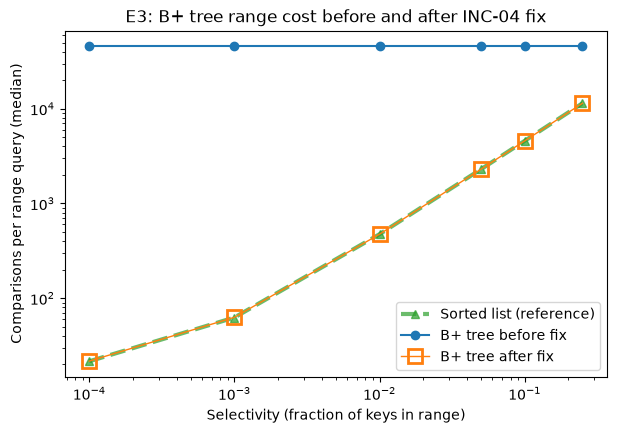

In [12]:
e3_all = df[(df.experiment == "E3_range_tempo")
            & (((df.index_type == "bplus_tree") & df.code_version.isin(["5be54e9", "e4a0cfb"]))
               | ((df.index_type == "sorted_list") & (df.code_version == "e4a0cfb")))].copy()

labels = {("bplus_tree", "5be54e9"): "B+ tree before fix",
          ("bplus_tree", "e4a0cfb"): "B+ tree after fix",
          ("sorted_list", "e4a0cfb"): "Sorted list (reference)"}

styles = {("bplus_tree", "5be54e9"): dict(marker="o", color="tab:blue"),
          ("bplus_tree", "e4a0cfb"): dict(marker="s", color="tab:orange", markersize=10, markerfacecolor="none", markeredgewidth=2, linewidth=1),
          ("sorted_list", "e4a0cfb"): dict(marker="^", color="tab:green", linestyle="--", linewidth=3, alpha=0.7)}

fig, ax = plt.subplots(figsize=(7, 4.5))
for key in [("sorted_list", "e4a0cfb"), ("bplus_tree", "5be54e9"), ("bplus_tree", "e4a0cfb")]:
    g = e3_all[(e3_all.index_type == key[0]) & (e3_all.code_version == key[1])]
    med = g.groupby("operation_param").cmp_per_op.median()
    ax.plot(med.index, med.values, label=labels[key], **styles[key])

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Selectivity (fraction of keys in range)")
ax.set_ylabel("Comparisons per range query (median)")
ax.set_title("E3: B+ tree range cost before and after INC-04 fix")
ax.legend()
plt.savefig("figures/INC04_E3_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

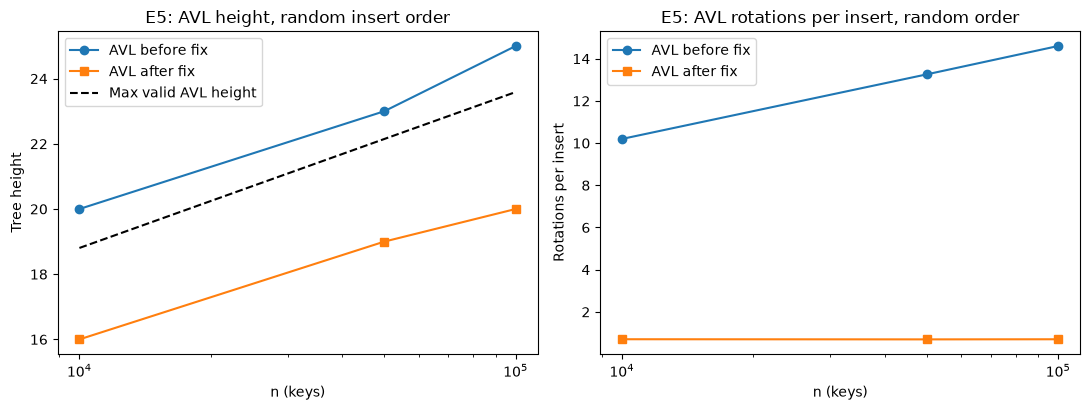

In [13]:
avl_plot = avl[avl.insert_order == "random"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for ver, style in [("before", dict(marker="o", color="tab:blue")),
                   ("after", dict(marker="s", color="tab:orange"))]:
    g = avl_plot[avl_plot.version == ver].groupby("n_keys")
    axes[0].plot(g.height.max(), label=f"AVL {ver} fix", **style)
    axes[1].plot(g.rot_per_insert.median(), label=f"AVL {ver} fix", **style)

ns = sorted(avl_plot.n_keys.unique())
axes[0].plot(ns, [1.44 * np.log2(n + 2) - 0.33 for n in ns], "k--", label="Max valid AVL height")
axes[0].set_xscale("log")
axes[0].set_xlabel("n (keys)")
axes[0].set_ylabel("Tree height")
axes[0].set_title("E5: AVL height, random insert order")
axes[0].legend()

axes[1].set_xscale("log")
axes[1].set_xlabel("n (keys)")
axes[1].set_ylabel("Rotations per insert")
axes[1].set_title("E5: AVL rotations per insert, random order")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/INC03_E5_before_after.png", dpi=150, bbox_inches="tight")
plt.show()